In [39]:
import onnxscript
import onnx
import tensorflow as tf
import cv2
import keras_cv
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import os
import json

In [25]:
# Setup GPU acceleration
gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("GPUs:", gpus)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [26]:
# Load the generated dataset
BATCH_SIZE = 8
IMAGE_SIZE = (512, 512)

def load_dataset(split):
    data_dir = Path("dataset/generated") / split
    image_dir = data_dir / "images"

    with (data_dir / "annotations.json").open() as f:
        coco = json.load(f)

    annotations_by_image = {}

    for annotation in coco["annotations"]:
        annotations_by_image.setdefault(
            annotation["image_id"], []
        ).append(annotation)

    image_records = []

    for image_info in coco["images"]:
        annotations = annotations_by_image.get(
            image_info["id"], []
        )

        boxes = []
        classes = []

        for annotation in annotations:
            # COCO xywh -> KerasCV xyxy
            x, y, w, h = annotation["bbox"]

            boxes.append([
                x,
                y,
                x + w,
                y + h,
            ])

            # One class: brick = 0
            classes.append(0)

         # Ensure consistent shapes, even for images with no bricks.
        boxes = np.asarray(boxes, dtype=np.float32).reshape(-1, 4)
        classes = np.asarray(classes, dtype=np.float32)

        image_records.append((
            str(image_dir / image_info["file_name"]),
            boxes,
            classes,
        ))

    def load_sample(path, boxes, classes):
        image = tf.io.read_file(path)
        image = tf.io.decode_jpeg(image, channels=3)
        image = tf.cast(image, tf.float32)

        # Get original image dimensions.
        original_shape = tf.shape(image)
        original_height = tf.cast(original_shape[0], tf.float32)
        original_width = tf.cast(original_shape[1], tf.float32)

        # Convert bounding boxes to float32.
        boxes = tf.cast(boxes, tf.float32)
        classes = tf.cast(classes, tf.float32)

        # Scale bounding boxes to match the resized image.
        scale_x = IMAGE_SIZE[1] / original_width
        scale_y = IMAGE_SIZE[0] / original_height

        boxes *= tf.stack([
            scale_x,
            scale_y,
            scale_x,
            scale_y,
        ])

        # Resize every image to the same dimensions.
        image = tf.image.resize(image, IMAGE_SIZE)
        image.set_shape((*IMAGE_SIZE, 3))

        return {
            "images": image,
            "bounding_boxes": {
                "boxes": boxes,
                "classes": classes,
            },
        }

    dataset = tf.data.Dataset.from_generator(
        lambda: iter(image_records),
        output_signature=(
            tf.TensorSpec(shape=(), dtype=tf.string),
            tf.TensorSpec(shape=(None, 4), dtype=tf.float32),
            tf.TensorSpec(shape=(None,), dtype=tf.float32),
        ),
    )

    dataset = dataset.map(
        load_sample,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.ragged_batch(
        BATCH_SIZE,
        drop_remainder=True,
    )

    return dataset


train_dataset = load_dataset("train")
val_dataset = load_dataset("val")

In [27]:
# Augmentation
augmenter = keras_cv.layers.RandomFlip(
    mode="horizontal",
    bounding_box_format="xyxy",
)

train_dataset = train_dataset.map(
    augmenter,
    num_parallel_calls=tf.data.AUTOTUNE,
)

# No random augmentation on validation data.

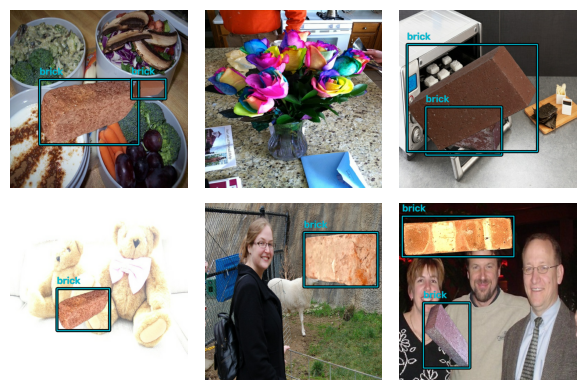

In [28]:
# Visualize data to check for abnormalities
images = next(iter(train_dataset))

keras_cv.visualization.plot_bounding_box_gallery(
    images["images"],
    value_range=(0, 255),
    bounding_box_format="xyxy",
    y_true=images["bounding_boxes"],
    rows=2,
    cols=3,
    class_mapping={0: "brick"},
    show=True,
)

In [29]:
# Load a YOLOv8 backbone pretrained on COCO.
backbone = keras_cv.models.YOLOV8Backbone.from_preset(
    "yolo_v8_s_backbone_coco"
)

# Create a detector with one class: brick.
model = keras_cv.models.YOLOV8Detector(
    num_classes=1,
    bounding_box_format="xyxy",
    backbone=backbone,
    fpn_depth=1,
)

# model.summary()

In [30]:
# Compile the starting model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4,
        global_clipnorm=10.0,
    ),
    classification_loss="binary_crossentropy",
    box_loss="ciou",
    jit_compile=False,
)

In [31]:
# Diagnose the database because something went wrong :(
def inspect_dataset(dataset, name):
    print(f"\n--- {name} ---")

    total_images = 0
    total_boxes = 0
    empty_images = 0
    bad_images = 0
    bad_boxes = 0

    for batch in dataset:
        images = batch["images"].numpy()
        boxes = batch["bounding_boxes"]["boxes"]
        classes = batch["bounding_boxes"]["classes"]

        for i in range(images.shape[0]):
            total_images += 1

            image = images[i]

            if not np.isfinite(image).all():
                bad_images += 1

            b = boxes[i].numpy()
            c = classes[i].numpy()

            if len(b) == 0:
                empty_images += 1
                continue

            total_boxes += len(b)

            # Check for invalid coordinates.
            valid = (
                np.isfinite(b).all(axis=1)
                & (b[:, 0] >= 0)
                & (b[:, 1] >= 0)
                & (b[:, 2] <= IMAGE_SIZE[1])
                & (b[:, 3] <= IMAGE_SIZE[0])
                & (b[:, 2] > b[:, 0])
                & (b[:, 3] > b[:, 1])
            )

            if not valid.all():
                bad_boxes += np.count_nonzero(~valid)

            if not np.isfinite(c).all():
                bad_boxes += 1

    print(f"Images:          {total_images}")
    print(f"Bounding boxes:  {total_boxes}")
    print(f"Empty images:    {empty_images}")
    print(f"Invalid images:  {bad_images}")
    print(f"Invalid boxes:   {bad_boxes}")


inspect_dataset(train_dataset, "Training")
inspect_dataset(val_dataset, "Validation")


--- Training ---
Images:          4000
Bounding boxes:  4174
Empty images:    788
Invalid images:  0
Invalid boxes:   0

--- Validation ---
Images:          496
Bounding boxes:  500
Empty images:    112
Invalid images:  0
Invalid boxes:   0


In [32]:
# Train the model
# Setup Checkpoints
# Since you're only saving weights, you should use the .weights.h5 extension.
# If you're saving the whole model, you would use the .keras extension instead
checkpoint_path = "training_1/cp.weights.h5"
checkpoint_dir = os.path.dirname(checkpoint_path)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "checkpoints/brick_detector.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1,
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[tf.keras.callbacks.TerminateOnNaN(), checkpoint, early_stopping],
)

Epoch 1/30


/home/abuddies/projects/brickid/training/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


    500/Unknown 70s 105ms/step - box_loss: 2.3311 - class_loss: 100.5997 - loss: 102.9307

I0000 00:00:1794034591.041621   28004 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 11716619444724242872
I0000 00:00:1794034591.041660   28004 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 813449708507752815
I0000 00:00:1794034591.041664   28004 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 4307673220463662451
/home/abuddies/projects/brickid/training/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 30.09668, saving model to checkpoints/brick_detector.keras


I0000 00:00:1794034593.814923   28203 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 2404629987654488104
I0000 00:00:1794034593.814959   28203 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 13977502774841663726
I0000 00:00:1794034593.814963   28203 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 1388554790020043830


... (112 outputs left out)

500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - box_loss: 0.2844 - class_loss: 0.2187 - loss: 0.5031

I0000 00:00:1794036236.153145   28004 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 11716619444724242872
I0000 00:00:1794036236.153180   28004 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 813449708507752815
I0000 00:00:1794036236.153184   28004 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 4307673220463662451



Epoch 30: val_loss did not improve from 0.59758
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - box_loss: 0.2839 - class_loss: 0.2183 - loss: 0.5021 - val_box_loss: 0.3361 - val_class_loss: 0.2796 - val_loss: 0.6157


I0000 00:00:1794036237.674540   28203 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 2404629987654488104
I0000 00:00:1794036237.674576   28203 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 13977502774841663726
I0000 00:00:1794036237.674580   28203 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 1388554790020043830


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step
<class 'dict'>
dict_keys(['boxes', 'confidence', 'classes', 'num_detections'])
boxes <class 'numpy.ndarray'> (8, 100, 4)
confidence <class 'numpy.ndarray'> (8, 100)
classes <class 'numpy.ndarray'> (8, 100)
num_detections <class 'numpy.ndarray'> (8,)


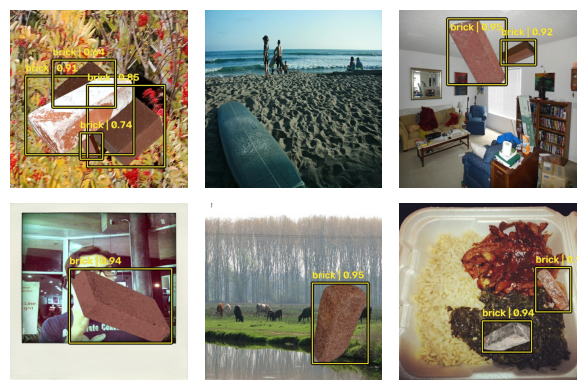

In [36]:
images = next(iter(val_dataset))["images"]

predictions = model.predict(images)

print(type(predictions))
print(predictions.keys())

for key, value in predictions.items():
    print(key, type(value), getattr(value, "shape", None))

keras_cv.visualization.plot_bounding_box_gallery(
    images,
    value_range=(0, 255),
    bounding_box_format="xyxy",
    y_pred=predictions,
    rows=2,
    cols=3,
    class_mapping={0: "brick"},
    show=True,
)

In [40]:
# Save the model (holy peak)
model.save("model/brick_detector.keras")
model.save_weights("model/brick_detector.weights.h5")
model.export(
    "model/brick_detector.onnx",
    format="onnx",
    input_signature=[
        tf.TensorSpec(
            shape=(None, 512, 512, 3),
            dtype=tf.float32,
            name="images",
        )
    ],
)

ImportError: This requires the tf2onnx module. You can install it via `pip install tf2onnx`